In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Olist E-Commerce Sales Analysis

## Merging the tables

To make the business questions easier to query, I merged 7 of the 9 tables into one order-item level table (113,425 rows). I started from `orders` and used left joins, so no order was dropped. Each join uses `validate=`, so pandas raises an error if the relationship is not what I expect.

| Step | Table added | Join key | Relationship | Rows after join |
|---|---|---|---|---|
| 1 | customers | customer_id | many-to-one | 99,441 |
| 2 | order_items | order_id | one-to-many | 113,425 |
| 3 | products | product_id | many-to-one | 113,425 |
| 4 | payments (aggregated per order) | order_id | many-to-one | 113,425 |
| 5 | reviews (aggregated per order) | order_id | many-to-one | 113,425 |
| 6 | category translation | product_category_name | many-to-one | 113,425 |

Row check: 112,650 item rows + 775 orders without items = 113,425.

Notes:
- `payments` and `reviews` can have several rows per order (several payments, several reviews). I first aggregated each to one row per `order_id` (`payment_total`, `payment_count`, `review_score_avg`, `review_count`). Joining them directly would multiply rows and double-count money.
- **Order-level columns** (`payment_total`, `payment_count`, `review_score_avg`, `review_count`) repeat on every item row of the same order. They must not be summed on this table; money is summed from item `price`, and order counts use distinct `order_id`.
- 775 orders have no items (603 unavailable, 164 canceled, 8 in other early statuses), so their item columns are empty. They are kept for the cancellation analysis.
- 1,603 item rows have no product category; I labeled them "Unknown" instead of dropping them, since they are real sales.
- 24 rows had categories missing from the translation table (2 categories); I added the English names manually. Check: 775 + 1,603 + 24 = 2,402 missing English names before the fixes.
- Not merged: sellers and geolocation (not needed for these questions; geolocation has many rows per zip prefix).

In [2]:
orders = pd.read_csv("data/olist_orders_dataset.csv")   # one row per order
customers = pd.read_csv("data/olist_customers_dataset.csv")   # customer_id is created per order; customer_unique_id identifies the person
len(orders), len(customers)   # 99,441 rows each

(99441, 99441)

In [3]:
merged = orders.merge(customers, on="customer_id", how="left", validate="m:1")   # each order has exactly one customer
merged.shape[0]   # 99,441: no rows added or lost
customers.isnull().sum()   # no missing values in the customer table

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

In [4]:
order_items = pd.read_csv("data/olist_order_items_dataset.csv")   # one row per item in an order
order_items.shape[0]   # 112,650 item rows
merged_order_items = merged.merge(order_items, on="order_id", how="left", validate="1:m")   # one order, many items
merged_order_items.shape[0]   # 113,425 = 112,650 item rows + 775 orders without items

113425

In [5]:
merged_order_items["product_id"].isna().sum()   # 775 orders have no item
merged_order_items[merged_order_items["product_id"].isna()]["order_status"].value_counts()   # mostly unavailable (603) and canceled (164)

order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64

In [6]:
merged_order_items.dtypes   # dates are stored as text (object); converted to datetime later

order_id                          object
customer_id                       object
order_status                      object
order_purchase_timestamp          object
order_approved_at                 object
order_delivered_carrier_date      object
order_delivered_customer_date     object
order_estimated_delivery_date     object
customer_unique_id                object
customer_zip_code_prefix           int64
customer_city                     object
customer_state                    object
order_item_id                    float64
product_id                        object
seller_id                         object
shipping_limit_date               object
price                            float64
freight_value                    float64
dtype: object

In [7]:
products = pd.read_csv("data/olist_products_dataset.csv")   # one row per product
products["product_id"].is_unique   # True, so the join cannot duplicate rows
merged_products = merged_order_items.merge(products, on="product_id", how="left", validate="m:1")   # many items, one product
merged_products.shape[0]   # still 113,425

113425

In [8]:
merged_products[merged_products["product_id"].notna()]["product_category_name"].isna().sum()   # 1,603 item rows whose product has no category

np.int64(1603)

In [9]:
mask = merged_products["product_category_name"].isna() & merged_products["product_id"].notna()
null_rows = merged_products[mask]   # item rows without a category
null_rows["product_id"].nunique(), null_rows["seller_id"].nunique()   # 610 products from 257 sellers: no single seller explains it

(610, 257)

In [10]:
payments = pd.read_csv("data/olist_order_payments_dataset.csv")   # one row per payment of an order
payments.shape[0]   # 103,886
types_per_order = payments.groupby("order_id")["payment_type"].nunique()
flags = types_per_order > 1
flags.sum()   # 2,246 orders paid with more than one payment type

np.int64(2246)

In [11]:
pay_summary = payments.groupby("order_id").agg(
    payment_total=("payment_value", "sum"),   # total paid for the order
    payment_count=("payment_sequential", "count"),   # number of payment rows
).reset_index()
pay_summary["order_id"].is_unique   # True: one row per order
merged_payments = merged_products.merge(pay_summary, on="order_id", how="left", validate="m:1")   # many item rows, one payment summary
merged_payments.shape[0]   # still 113,425

113425

In [12]:
reviews = pd.read_csv("data/olist_order_reviews_dataset.csv")   # one row per review
reviews.shape[0]   # 99,224
reviews["order_id"].is_unique   # False: some orders have more than one review
reviews_per_order = reviews.groupby("order_id")["review_id"].nunique()
flags_1 = reviews_per_order > 1
flags_1.sum()   # 547 orders with more than one review

np.int64(547)

In [13]:
reviews_summary = reviews.groupby("order_id").agg(
    review_score_avg=("review_score", "mean"),   # average score per order
    review_count=("review_id", "count"),   # number of reviews per order
).reset_index()
reviews_summary["order_id"].is_unique   # True
merged_reviews = merged_payments.merge(reviews_summary, on="order_id", how="left", validate="m:1")   # many item rows, one review summary
merged_reviews.shape[0]   # still 113,425

113425

In [14]:
category = pd.read_csv("data/product_category_name_translation.csv")   # Portuguese to English category names
category.shape[0]   # 71
category["product_category_name"].is_unique   # True
merged_total = merged_reviews.merge(category, on="product_category_name", how="left", validate="m:1")   # many items, one category
merged_total.shape[0]   # still 113,425
merged_total["product_category_name_english"].isna().sum()   # 2,402 = 775 orders without items + 1,603 items without category + 24 untranslated

np.int64(2402)

In [15]:
mask = merged_total["product_category_name"].notna() & merged_total["product_category_name_english"].isna()
missing_trans = merged_total[mask]   # categories missing from the translation table
missing_trans["product_category_name"].value_counts()   # 2 categories, 24 rows

product_category_name
portateis_cozinha_e_preparadores_de_alimentos    15
pc_gamer                                          9
Name: count, dtype: int64

In [16]:
fix = {
    "pc_gamer": "pc_gamer",
    "portateis_cozinha_e_preparadores_de_alimentos": "portable_kitchen_and_food_preparers",   # added manually
}
merged_total["product_category_name_english"] = merged_total["product_category_name_english"].fillna(
    merged_total["product_category_name"].map(fix)
)
merged_total["product_category_name_english"].isna().sum()   # 2,378 left

np.int64(2378)

In [17]:
has_item = merged_total["product_id"].notna()
merged_total.loc[has_item, "product_category_name_english"] = (
    merged_total.loc[has_item, "product_category_name_english"].fillna("Unknown")   # item rows without a category are labeled "Unknown", not dropped
)
merged_total["product_category_name_english"].isna().sum()   # 775: only the orders without items
merged_total.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'customer_unique_id', 'customer_zip_code_prefix', 'customer_city',
       'customer_state', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value',
       'product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm',
       'payment_total', 'payment_count', 'review_score_avg', 'review_count',
       'product_category_name_english'],
      dtype='object')

## Q1. Order volume by customer state

Orders are counted as distinct `order_id` per `customer_state` (an order can have several item rows, so row counts would overcount). The state totals add up to 99,441, matching the `orders` table.

**Finding:** Demand is highly concentrated. SP (São Paulo) alone has 41,746 orders (42.0% of the total), followed by RJ (12,852) and MG (11,635). Together, these three southeastern states account for 66.6% of all orders.

**Interpretation:** This is consistent with these being the most populated and economically developed states in Brazil, but this dataset has no population data, so that explanation is an assumption, not a result.

**Note:** This counts all orders, whatever their status.

**Use:** It shows where demand is concentrated and could help prioritize regional resources. Order count alone does not show profit.

In [18]:
# Orders per customer state: count distinct order_id, since an order can have several item rows
state_orders = merged_total.groupby("customer_state")["order_id"].nunique().sort_values(ascending=False)
state_orders.head(10)

customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
Name: order_id, dtype: int64

In [19]:
state_orders.sum()   # NEW check: 99,441, same as the orders table
state_orders.head(3).sum() / state_orders.sum()   # top 3 states: 66.6%
state_orders.head(1).sum() / state_orders.sum()   # SP alone: 42.0%

np.float64(0.41980671956235355)

## Q2. Cancellation rate

Computed on the orders table (99,441 orders, one row per order), not the merged table, to avoid counting orders with several items more than once.

Finding: Cancellations are rare. 625 orders (0.63%) are canceled, and 609 (0.61%) are unavailable (item not available). 97.0% of orders are delivered. I report the two statuses separately because they mean different things; together they are about 1.2%.

Note: About 1.7% of orders are still in progress (shipped, invoiced, processing, created, approved). They are neither delivered nor canceled, so the delivered share is a lower bound of the final fulfillment rate.

Important for the sales figures: not every canceled or unavailable order is empty. 467 of them still have item rows, so they must be excluded when computing sales (see the definition of sales below).

In [20]:
# Share of orders by status, computed on the orders table (one row per order)
orders["order_status"].value_counts(normalize=True)
orders["order_status"].value_counts(normalize=True)[["canceled", "unavailable"]]   # 0.63% canceled, 0.61% unavailable

order_status
canceled       0.006285
unavailable    0.006124
Name: proportion, dtype: float64

In [21]:
# Canceled or unavailable orders that still have item rows
bad_ids = orders.loc[orders["order_status"].isin(["canceled", "unavailable"]), "order_id"]
order_items.loc[order_items["order_id"].isin(bad_ids), "order_id"].nunique()   # expected 467 = 461 canceled + 6 unavailable

467

## Definition of sales

Sales = sum of item `price` (freight excluded) over item rows of orders that were **not** canceled or unavailable. Orders still in progress are kept. Excluding canceled and unavailable orders removes about 0.72% of total item value, so the conclusions below change only slightly.

In [22]:
# Item rows count as sales unless the order was canceled or unavailable
has_item = merged_total["product_id"].notna()
not_sold = merged_total["order_status"].isin(["canceled", "unavailable"])


In [23]:
lost_value = merged_total.loc[has_item & not_sold, "price"].sum()   # item value of canceled/unavailable orders
total_value = merged_total["price"].sum()   # item value before the exclusion
lost_value / total_value   # share of item value that is not real sales

np.float64(0.007154613683700376)

In [24]:
sales_items = merged_total.loc[has_item & ~not_sold].copy()   # item rows used for all sales figures below
sales_items["order_purchase_timestamp"] = pd.to_datetime(sales_items["order_purchase_timestamp"])   # dates are stored as text
sales_items["month"] = sales_items["order_purchase_timestamp"].dt.to_period("M")   # order month
sales_items["price"].sum()   # total sales after the exclusion

np.float64(13494400.740000002)

## Definition of sales

Sales = sum of item price (excludes freight), grouped by the month the order was placed, using the sales definition above. I use Jan 2017 to Aug 2018 only: the dataset covers the start and the end of the period only partially (for example, sales were about 208 BRL in Sep 2016 and 145 BRL in Sep 2018), so these months would distort the trend.

## Q3. Monthly sales

Finding:
- Sales peak in Nov 2017 at about 1.00M, then fall back in Dec 2017 (about 0.74M). The top day in Nov 2017 is 2017-11-24, which is Black Friday 2017, with about 0.15M, roughly 15% of that month's sales. This is consistent with a Black Friday effect, but the dataset has no promotion data, so it is not proven.
- Sales are higher in 2018: monthly sales stay between about 0.84M and 0.99M from Jan to Aug 2018, compared with 0.12M to 0.66M in Jan to Oct 2017. Comparing the same months (Jan to Aug), 2018 sales are about 2.38 times those of 2017. Part of this comes from the low starting point of the platform in early 2017.
- Where the growth comes from: the number of orders grew by a factor of 2.37 and the average order value by a factor of 1.00 (2.37 × 1.00 = 2.38), so growth came almost entirely from more orders; the average order value stayed flat.


In [25]:
# Monthly sales = sum of item price (freight excluded) by order month
monthly = sales_items.groupby("month")["price"].sum()
monthly

month
2016-09        207.86
2016-10      44507.30
2016-12         10.90
2017-01     120098.27
2017-02     244959.35
2017-03     368341.32
2017-04     353842.98
2017-05     503159.19
2017-06     429916.61
2017-07     492287.30
2017-08     568245.79
2017-09     621415.91
2017-10     660179.62
2017-11    1003862.14
2017-12     742183.79
2018-01     945456.29
2018-02     837895.43
2018-03     981051.06
2018-04     993592.98
2018-05     992871.75
2018-06     863265.53
2018-07     878044.27
2018-08     848860.10
2018-09        145.00
Freq: M, Name: price, dtype: float64

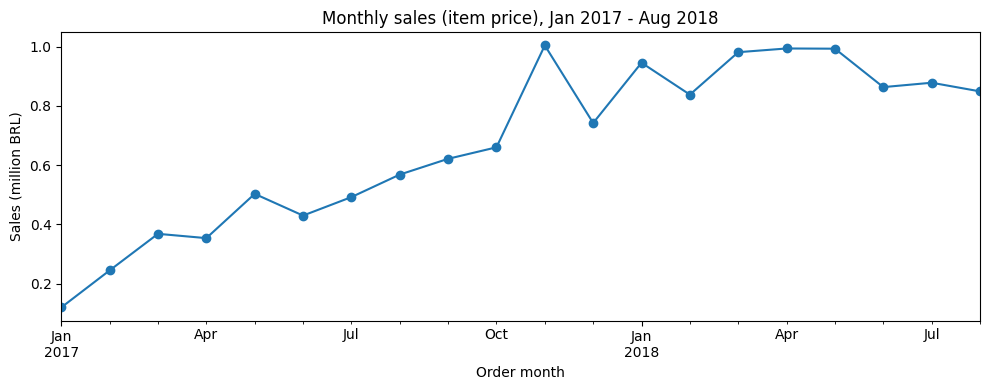

In [26]:
monthly_clean = monthly["2017-01":"2018-08"]   # months with full coverage only
ax = (monthly_clean / 1e6).plot(marker="o", figsize=(10, 4), title="Monthly sales (item price), Jan 2017 - Aug 2018")   # divided by 1e6 so the axis is in millions
ax.set_xlabel("Order month")
ax.set_ylabel("Sales (million BRL)")
plt.tight_layout()
plt.show()

In [27]:
y2017 = monthly["2017-01":"2017-08"].sum()   # same months in both years: Jan to Aug
y2018 = monthly["2018-01":"2018-08"].sum()
y2018 / y2017   # 2.38 after excluding canceled/unavailable orders

np.float64(2.382795488237225)

In [28]:
# Split the growth into more orders vs higher value per order
monthly_orders = sales_items.groupby("month")["order_id"].nunique()   # distinct orders per month
orders17 = monthly_orders["2017-01":"2017-08"].sum()
orders18 = monthly_orders["2018-01":"2018-08"].sum()

orders_ratio = orders18 / orders17   # growth in the number of orders
aov_ratio = (y2018 / orders18) / (y2017 / orders17)   # growth in average order value
orders_ratio, aov_ratio, orders_ratio * aov_ratio   # the product equals y2018 / y2017

(np.float64(2.3725733534261146),
 np.float64(1.0043084589129136),
 np.float64(2.3827954882372246))

In [29]:
# Is the Nov 2017 peak concentrated on one day?
nov = sales_items[sales_items["month"] == "2017-11"]
daily_nov = nov.groupby(nov["order_purchase_timestamp"].dt.date)["price"].sum()
daily_nov.sort_values(ascending=False).head(5)   # check whether 2017-11-24 (Black Friday) is the top day

order_purchase_timestamp
2017-11-24    152653.74
2017-11-25     60923.48
2017-11-27     47923.66
2017-11-28     47886.55
2017-11-26     44976.28
Name: price, dtype: float64

## Q4. Top 10 product categories by sales

Sales = sum of item price (excludes freight) per English category name, using the sales definition above. Orders without items are excluded. Item rows with no category (1,603 rows before the exclusion of canceled orders) are labeled "Unknown" and kept.

Finding:
- The top three categories are health_beauty (about 1.26M), watches_gifts (about 1.20M) and bed_bath_table (about 1.04M).
- No single category dominates: the largest, health_beauty, is 9.3% of total sales. The top 3 account for 25.9% of sales and the top 10 for 62.4%; the remaining 64 categories share the other 37.6%.
- "Unknown" accounts for 1.3% of sales, so missing categories do not distort the ranking.

Note: Only the top 10 are shown; the remaining categories form a long tail that I did not examine.

In [30]:
# Top 10 categories by sales (item price)
category_ranking = sales_items.groupby("product_category_name_english")["price"].sum().sort_values(ascending=False).head(10)
category_ranking

product_category_name_english
health_beauty            1255695.13
watches_gifts            1198185.21
bed_bath_table           1035964.06
sports_leisure            979740.92
computers_accessories     904322.02
furniture_decor           727465.05
housewares                626825.80
cool_stuff                620770.49
auto                      586585.73
garden_tools              481009.94
Name: price, dtype: float64

In [31]:
category_share = category_ranking / sales_items["price"].sum()   # share of total sales
category_share
category_share.head(3).sum()   # top 3 categories
category_share.sum()   # NEW: top 10 categories
sales_items["product_category_name_english"].nunique()   # NEW: number of categories in total
sales_items.loc[sales_items["product_category_name_english"] == "Unknown", "price"].sum() / sales_items["price"].sum()   # NEW: share of sales with an unknown category

np.float64(0.013233084850568915)

In [32]:
# Ranking by units sold instead of sales: categories in only one ranking differ in price per item
sales_items.groupby("product_category_name_english")["order_item_id"].count().sort_values(ascending=False).head(10)

product_category_name_english
bed_bath_table           11097
health_beauty             9634
sports_leisure            8590
furniture_decor           8298
computers_accessories     7781
housewares                6915
watches_gifts             5970
telephony                 4527
garden_tools              4328
auto                      4204
Name: order_item_id, dtype: int64

In [33]:
sales_items["product_category_name_english"].nunique() - 10   # categories outside the top 10 ("Unknown" counts as one)

64

## Summary and limitations

- Demand is concentrated in the southeast: SP, RJ and MG account for 66.6% of orders.
- Cancellations are rare (about 1.2% canceled or unavailable), but they still affect sales figures if their items are not excluded.
- Sales grew strongly from 2017 to 2018, almost entirely through more orders; the average order value stayed flat.
- Limitations: no cost or profit data, so order counts and sales do not show profitability; no population data, so the state ranking is not normalized; Black Friday is an assumption; the first and last months of the dataset are incomplete and were left out; the category ranking was not checked below the top 10.